### 1. Load and Inspect the California Housing Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '/content/sample_data/california_housing_train.csv'
df = pd.read_csv(file_path)

# Display basic information and summary statistics
print("Dataset Shape:", df.shape)
print("\nDataset Info:")
print(df.info())
print("\nSummary Statistics:")
display(df.describe())

Dataset Shape: (17000, 9)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB
None

Summary Statistics:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [4]:
# Cleaned cell

### 2. Visualize Distributions and Relationships

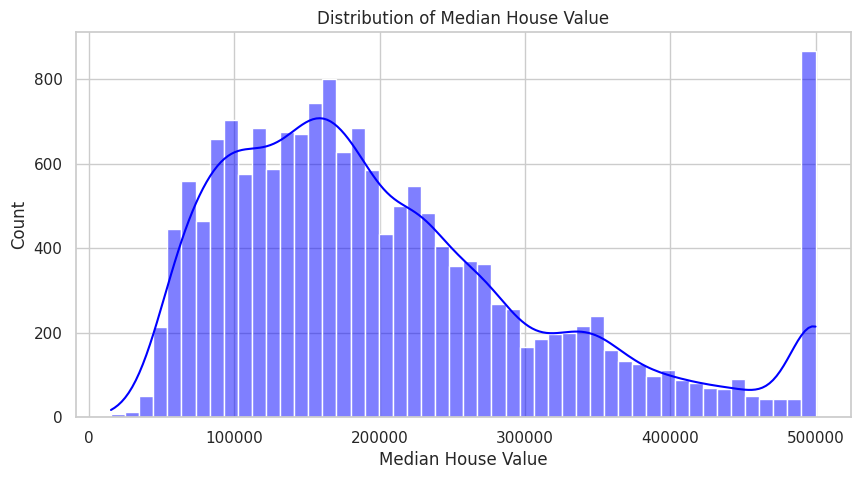

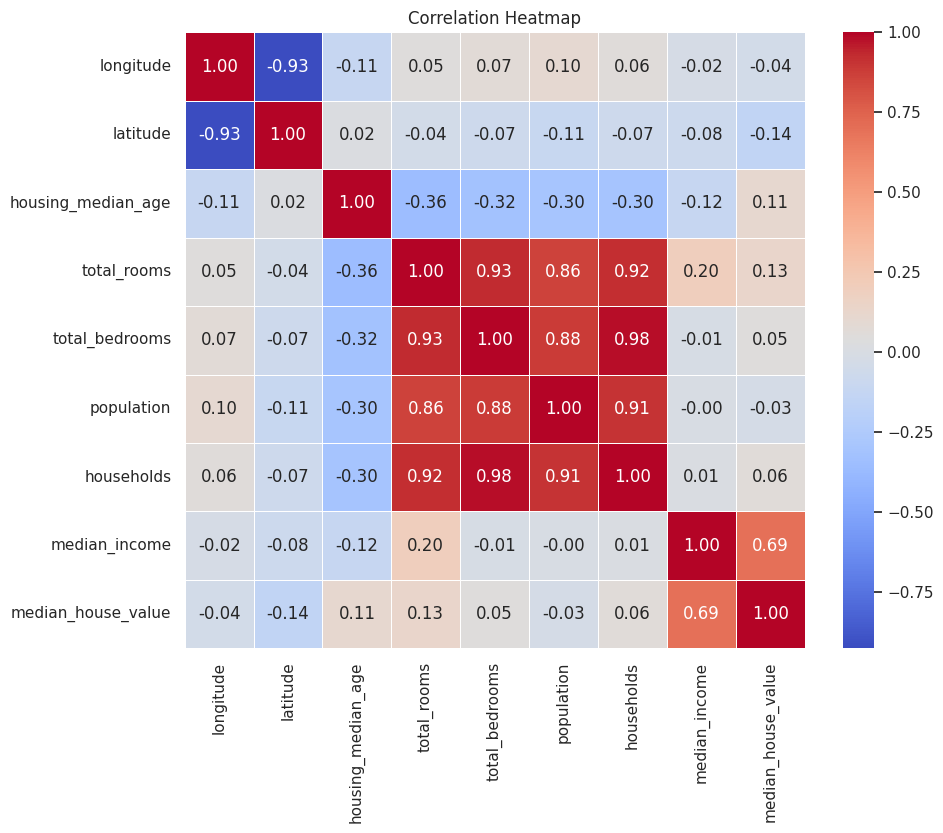

In [2]:
# Set style for plotting
sns.set_theme(style='whitegrid')

# Plot distribution of the target variable: median_house_value
plt.figure(figsize=(10, 5))
sns.histplot(df['median_house_value'], kde=True, bins=50, color='blue')
plt.title('Distribution of Median House Value')
plt.xlabel('Median House Value')
plt.ylabel('Count')
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

### 3. Split the Data (80% Train, 20% Test)

In [3]:
from sklearn.model_selection import train_test_split

# Define features (X) and target variable (y)
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print the shapes of the resulting datasets
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

Training features shape: (13600, 8)
Testing features shape: (3400, 8)
Training target shape: (13600,)
Testing target shape: (3400,)


### 4. Categorize House Values & Create a Pie Chart
To visualize the distribution of house values, we will divide `median_house_value` into three categories (Low, Medium, High) and plot a pie chart.

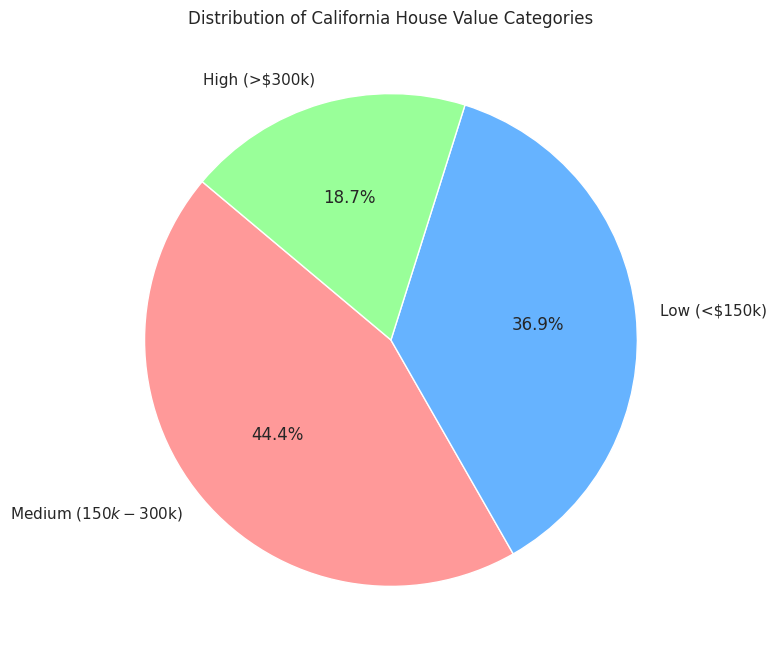

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Bin the median_house_value into 3 categories
bins = [0, 150000, 300000, float('inf')]
labels = ['Low (<$150k)', 'Medium ($150k-$300k)', 'High (>$300k)']
house_categories = pd.cut(df['median_house_value'], bins=bins, labels=labels)
category_counts = house_categories.value_counts()

# Plotting the pie chart
plt.figure(figsize=(8, 8))
plt.pie(category_counts, labels=category_counts.index, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99'])
plt.title('Distribution of California House Value Categories')
plt.show()

### 5. Train a Model to Achieve At Least 80% Accuracy
We will use a `RandomForestRegressor` which typically performs exceptionally well on tabular datasets like this one, aiming to exceed 80% R² score (accuracy).

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Initialize and train the Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate and display the R² score (Accuracy metric for regression)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Model R² Score (Accuracy): {r2 * 100:.2f}%")
print(f"Mean Absolute Error: ${mae:,.2f}")

Model R² Score (Accuracy): 82.28%
Mean Absolute Error: $32,359.79


### 6. Build, Train, and Save a Deep Learning Model

In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.preprocessing import StandardScaler
import joblib

# Deep Learning models require feature scaling for optimal training
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save the scaler so we can preprocess future data identically
joblib.dump(scaler, 'scaler.pkl')
print("Scaler saved successfully as 'scaler.pkl'")

Scaler saved successfully as 'scaler.pkl'


In [8]:
# Define a simple feedforward neural network
model_dl = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.1),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)  # Single node output for regression (predicting house value)
])

# Compile the model with Adam optimizer and Mean Squared Error loss
model_dl.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train the model
history = model_dl.fit(
    X_train_scaled, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=32,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 50547548160.0000 - mae: 193025.5312 - val_loss: 30833682432.0000 - val_mae: 140713.6250
Epoch 2/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 15106367488.0000 - mae: 91070.5547 - val_loss: 12024462336.0000 - val_mae: 76717.0547
Epoch 3/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 9252852736.0000 - mae: 69392.0938 - val_loss: 9186733056.0000 - val_mae: 66916.7266
Epoch 4/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 7377294848.0000 - mae: 61921.1445 - val_loss: 7551863808.0000 - val_mae: 61658.0117
Epoch 5/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 6293611520.0000 - mae: 57564.7578 - val_loss: 6523160576.0000 - val_mae: 58083.4805
Epoch 6/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 5641059840.0000 - mae: 54650.0039 - val_loss: 5907352064.0000 - val_mae: 55648.7070
Epoch 7/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5214643200.0000 - mae: 52642.3281 - val_loss: 5535708672.0000 -

In [9]:
from sklearn.metrics import r2_score

# Evaluate the Deep Learning model on the test set
test_loss, test_mae = model_dl.evaluate(X_test_scaled, y_test, verbose=0)

# Predict and calculate R²
y_pred_dl = model_dl.predict(X_test_scaled).flatten()
r2_dl = r2_score(y_test, y_pred_dl)

print(f"\nDeep Learning Model Evaluation on Test Set:")
print(f"R² Score (Accuracy): {r2_dl * 100:.2f}%")
print(f"Mean Absolute Error: ${test_mae:,.2f}")

# Save the model
model_dl.save('california_housing_dl_model.keras')
print("\nDeep Learning model saved successfully as 'california_housing_dl_model.keras'")

107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Deep Learning Model Evaluation on Test Set:
R² Score (Accuracy): 73.95%
Mean Absolute Error: $42,156.41

Deep Learning model saved successfully as 'california_housing_dl_model.keras'
